# Decision Trees and Random Forests

## Problem Statement
The objective is to build and compare a Decision Tree Classifier and a Random Forest Classifier to predict the presence of heart disease. The models will be evaluated, overfitting will be analyzed, and feature importance and cross-validation will be explored.

## Dataset Information
- **Dataset:** Heart Disease Dataset (`heart.csv`)
- **Total Rows:** 1,025
- **Total Columns:** 14
- **Input Features:** 13
- **Target Column:** `target`
- **Missing Values:** 0
- **Data Types:** 13 integer columns and 1 floating-point column
- **Memory Usage:** Approximately 112.2 KB

The dataset contains patient-related attributes such as age, sex, chest pain type, cholesterol, resting blood pressure, maximum heart rate, and other clinical measurements.

The `target` column represents the classification outcome:
- `0` — Absence of heart disease
- `1` — Presence of heart disease

## Objective
Train a Decision Tree Classifier and a Random Forest Classifier, compare their performance, control overfitting, visualize the decision tree, identify important features, and evaluate performance using cross-validation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Data/heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
df.shape

(1025, 14)

In [4]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [6]:
df.duplicated().sum()

np.int64(723)

In [7]:
display(df["target"].value_counts().sort_index())

target
0    499
1    526
Name: count, dtype: int64

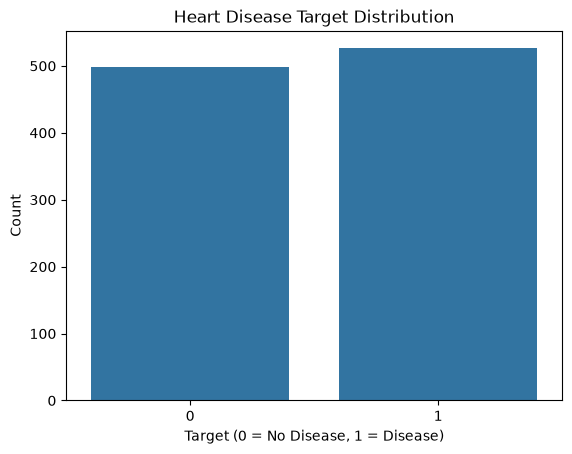

In [8]:
sns.countplot(data=df, x="target")
plt.title("Heart Disease Target Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Count")
plt.show()

In [9]:
display(
    df.corr(numeric_only=True)["target"]
      .drop("target")
      .sort_values(key=abs, ascending=False)
      .to_frame("Correlation with Target")
)

,Correlation with Target
oldpeak,-0.438441
exang,-0.438029
cp,0.434854
thalach,0.422895
ca,-0.382085
slope,0.345512
thal,-0.337838
sex,-0.279501
age,-0.229324
trestbps,-0.138772


In [10]:
from sklearn.model_selection import train_test_split

# Remove exact duplicate records before splitting
df = df.drop_duplicates().reset_index(drop=True)

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset shape:", df.shape)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Dataset shape: (302, 14)
Training set: (241, 13)
Testing set: (61, 13)


In [11]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [12]:

y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)


In [13]:
print(f"Training Accuracy: {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Testing Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 1.0000
Testing Accuracy:  0.8033

Confusion Matrix:
[[22  6]
 [ 6 27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.82      0.82      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



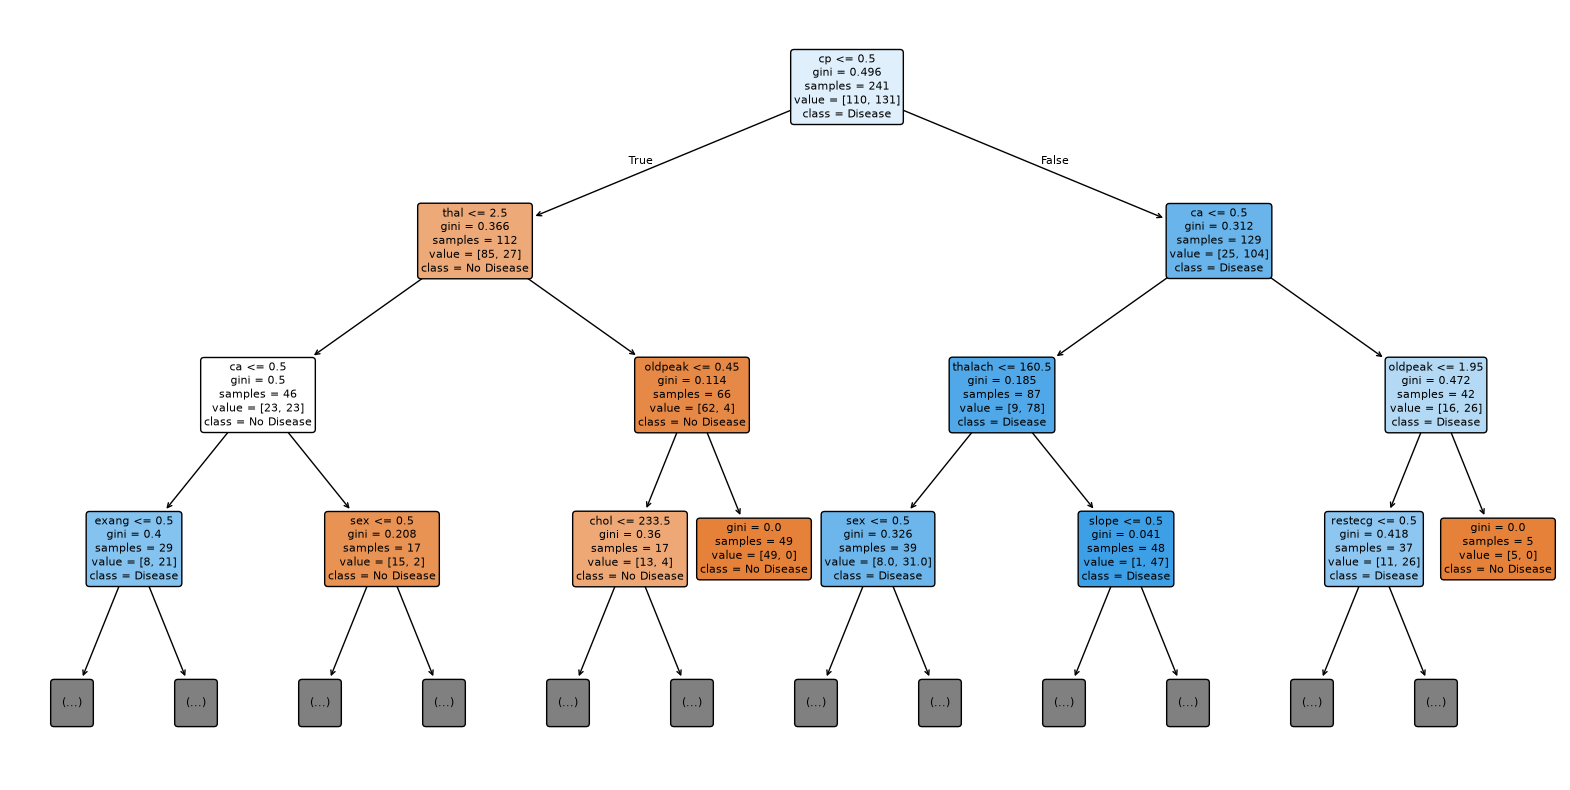

In [14]:
plt.figure(figsize=(20, 10))
plot_tree(
    dt,
    feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.show()

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

for depth in [3, 5, 7, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    print(
        f"max_depth={depth}: "
        f"Train Accuracy={train_acc:.4f}, "
        f"Test Accuracy={test_acc:.4f}"
    )

max_depth=3: Train Accuracy=0.8589, Test Accuracy=0.8033
max_depth=5: Train Accuracy=0.9419, Test Accuracy=0.7705
max_depth=7: Train Accuracy=0.9793, Test Accuracy=0.7705
max_depth=None: Train Accuracy=1.0000, Test Accuracy=0.8033


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [18]:

y_rf_train = rf.predict(X_train)
y_rf_test = rf.predict(X_test)

print(f"Training Accuracy: {accuracy_score(y_train, y_rf_train):.4f}")
print(f"Testing Accuracy:  {accuracy_score(y_test, y_rf_test):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_rf_test))

print("\nClassification Report:")
print(classification_report(y_test, y_rf_test))

Training Accuracy: 1.0000
Testing Accuracy:  0.7541

Confusion Matrix:
[[20  8]
 [ 7 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.71      0.73        28
           1       0.76      0.79      0.78        33

    accuracy                           0.75        61
   macro avg       0.75      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61



,Importance
cp,0.173969
thalach,0.131634
ca,0.105700
oldpeak,0.096577
thal,0.090418
age,0.083049
exang,0.073679
trestbps,0.072088
chol,0.067384
sex,0.040229


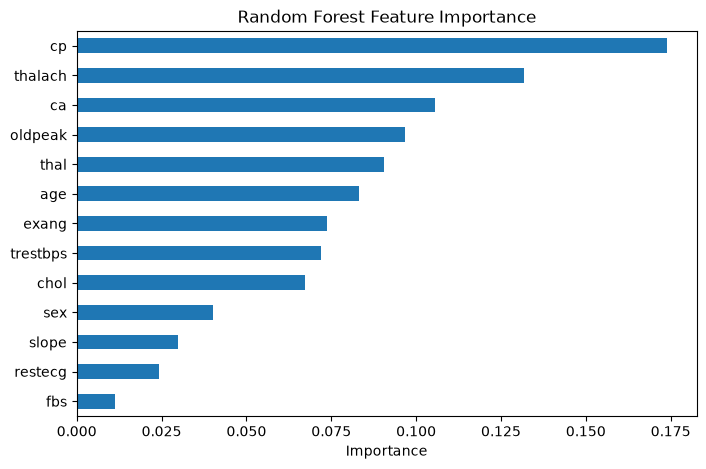

Decision Tree (depth=3): CV Accuracy = 0.7592 (± 0.0436)
Random Forest: CV Accuracy = 0.8504 (± 0.0387)


In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Identify the most important features in the Random Forest
importance = pd.Series(
    rf.feature_importances_, index=X.columns
).sort_values(ascending=False)

display(importance.to_frame("Importance"))

importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

# Compare models using the same stratified folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Decision Tree (depth=3)": DecisionTreeClassifier(
        max_depth=3, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="accuracy"
    )
    print(
        f"{name}: CV Accuracy = {scores.mean():.4f} "
        f"(± {scores.std():.4f})"
    )

In [20]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Tune Decision Tree
dt_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "criterion": ["gini", "entropy"]
}

dt_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_grid, cv=cv, scoring="accuracy", n_jobs=-1
)
dt_search.fit(X_train, y_train)

# Tune Random Forest
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", None]
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_grid, cv=cv, scoring="accuracy", n_jobs=-1
)
rf_search.fit(X_train, y_train)

# Evaluate the selected models on the untouched test set
for name, search in [
    ("Decision Tree", dt_search),
    ("Random Forest", rf_search)
]:
    model = search.best_estimator_
    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    print(f"Test accuracy: {accuracy_score(y_test, model.predict(X_test)):.4f}")


Decision Tree
Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV accuracy: 0.8094
Test accuracy: 0.7049

Random Forest
Best parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV accuracy: 0.8588
Test accuracy: 0.7705


In [21]:

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

selector = SelectFromModel(
    RandomForestClassifier(n_estimators=100, random_state=42),
    threshold="median"
)

models = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "model__max_depth": [3, 5, 7, None],
            "model__min_samples_leaf": [1, 2, 5]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [5, 10, None],
            "model__min_samples_leaf": [1, 2]
        }
    )
}

for name, (estimator, params) in models.items():
    for selection in [False, True]:
        steps = []
        if selection:
            steps.append(("selection", selector))
        steps.append(("model", estimator))

        search = GridSearchCV(
            Pipeline(steps),
            params,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )
        search.fit(X_train, y_train)

        predictions = search.predict(X_test)

        print(f"\n{name} | Feature selection: {selection}")
        print(f"CV accuracy: {search.best_score_:.4f}")
        print(f"Test accuracy: {accuracy_score(y_test, predictions):.4f}")
        print("Best parameters:", search.best_params_)

        if selection:
            fitted_selector = search.best_estimator_.named_steps["selection"]
            selected = X.columns[fitted_selector.get_support()]
            print("Selected features:", list(selected))
            print("Number selected:", len(selected))


Decision Tree | Feature selection: False
CV accuracy: 0.7802
Test accuracy: 0.7705
Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 5}

Decision Tree | Feature selection: True
CV accuracy: 0.8173
Test accuracy: 0.8033
Best parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 1}
Selected features: ['age', 'cp', 'thalach', 'exang', 'oldpeak', 'ca', 'thal']
Number selected: 7

Random Forest | Feature selection: False
CV accuracy: 0.8588
Test accuracy: 0.7705
Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}

Random Forest | Feature selection: True
CV accuracy: 0.8131
Test accuracy: 0.7869
Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Selected features: ['age', 'cp', 'thalach', 'exang', 'oldpeak', 'ca', 'thal']
Number selected: 7
